<a href="https://colab.research.google.com/github/aldo02032004/naufaldo.github.io/blob/main/2_ML_Dev_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **(Second development)**
# Figurative Language Classification using Machine Learning

## Setting Up the Program

### Installing all the needed library

In [2]:
%pip install -q ftfy PySastrawi datasets accelerate emoji
%pip install -q "great[text,ml] @ git+https://github.com/azmkto/GREAT-Tools.git"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### Importing the needed library

In [3]:
import io, re, gc, json, codecs, shutil, html
from google.colab import files, drive

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ftfy
import emoji
import nltk
from nltk.corpus import stopwords as nltk_stopwords
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedGroupKFold, GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (f1_score, classification_report, ConfusionMatrixDisplay,
                             precision_recall_fscore_support, log_loss, cohen_kappa_score)
from scipy.stats import bootstrap
from scipy.special import softmax
from scipy.optimize import minimize_scalar

import torch
from datasets import Dataset
from transformers import (AutoConfig, AutoTokenizer, AutoModelForSequenceClassification, Trainer,
                          TrainingArguments, EarlyStoppingCallback, set_seed)

from great import SLANG, MEDIA_MAP, normalize_majas, is_media_account, validate_export

In [4]:
nltk.download('stopwords', quiet=True)
pd.set_option('display.max_colwidth', None)   # show full texts in tables

# mixed-encoding CSVs: decode as UTF-8, and read only the bytes that fail as Windows-1252 (e.g. 0x92 = ’)
codecs.register_error('cp1252_fallback',
                      lambda e: (e.object[e.start:e.end].decode('cp1252', errors='replace'), e.end))

def read_uploaded_file(name, content):
    # some files have a title row above the header, so start from the row that holds 'Mentions'
    if name.lower().endswith(('.xlsx', '.xls')):
        peek = pd.read_excel(io.BytesIO(content), header=None, nrows=10)
        header_row = peek.index[peek.eq('Mentions').any(axis=1)][0]
        return pd.read_excel(io.BytesIO(content), header=header_row)

    text = content.decode('utf-8-sig', errors='cp1252_fallback')
    lines = text.splitlines()[:10]
    header_row = next(i for i, line in enumerate(lines) if 'Mentions' in line)
    sep = ';' if lines[header_row].count(';') > lines[header_row].count(',') else ','   # daily export uses ';'
    return pd.read_csv(io.StringIO(text), skiprows=header_row, sep=sep)

uploaded = files.upload()   # pick both files (CSV or Excel): the labeled training file and the file to predict
dataframes = {name: read_uploaded_file(name, content) for name, content in uploaded.items()}
for name, df in dataframes.items():
    print(name, df.shape)

# the file with a 'Majas' column is the training data, the other one gets predicted
training_df = next((df for df in dataframes.values() if 'Majas' in df.columns), None)
predict_df = next((df for df in dataframes.values() if 'Majas' not in df.columns), None)
assert training_df is not None, "No training file (with a 'Majas' column) uploaded."
assert predict_df is not None, "No file to predict uploaded."
training_df.head(1)

Saving train_data.xlsx - Sheet1.csv to train_data.xlsx - Sheet1.csv
Saving daily_16okt_Prabowo.csv to daily_16okt_Prabowo.csv
train_data.xlsx - Sheet1.csv (13146, 7)
daily_16okt_Prabowo.csv (6209, 13)


,x,Media,Author,Mentions,Sentiment,Emotion,Majas
0,2026-08-14 07:10:34,Threads,NaN,Kata seekor prabodoh asubiantolol : yg penting ternak suara buat pemilu 2029. Sebelom jadi bangkai najis harus 2 periode dong.,Negative,Anger,Sindiran


In [5]:
def prepare_time(data, date_col='Date'):
    # parse the date column into datetime and sort oldest -> newest
    data = data.rename(columns={date_col: 'Date'})
    data['Date'] = pd.to_datetime(data['Date'], format='mixed', dayfirst=True)
    return data.sort_values('Date')

# training_df has 'x' instead of 'Date' and lacks 'Type'
training_df1 = prepare_time(
    training_df[['x', 'Media', 'Mentions', 'Sentiment', 'Majas', 'Author']], date_col='x')
print(training_df1['Date'].min().strftime('%d %b %Y'), '-', training_df1['Date'].max().strftime('%d %b %Y'))
training_df1

01 Jan 2026 - 31 Aug 2026


,Date,Media,Mentions,Sentiment,Majas,Author
10020,2026-01-01 00:33:55,Tiktok,Prabowo sambut tahun baru obati duka bencana sumatera #prabowo #gerindra,Positive,Pujian,wiwingnofri2
3787,2026-01-01 02:10:01,Tiktok,"Senyum pak Prabowo saat disambut warga Tapanuli Selatan 🥹💗 Untuk kesekian kalinya pak prabowo berkunjung ke Sumatera dan sekarang beliau datang ke Tapanuli Selatan. Sebelumnya, Wakil Ketua DPR Sufmi Dasco Ahmad dan UKP Raffi Ahmad sudah berkunjung ke Aceh. Ini merupakan bukti bahwa Pemrintah bersana DPR RI hadir membawa dukungan dan bantuan untuk warga korban bencana Sumatera-Aceh 🥺❤ #prabowosubianto #presidenprabowo #tahunbaru2026 #tapanuliselatan #fyp",Positive,Pujian,maswowogemoy
7148,2026-01-01 03:04:10,Youtube,"Malam Tahun Baru di Tapanuli Selatan, Presiden Prabowo Bersama Warga Terdampak Bencana. prabowo #tapsel #indonesia.",Neutral,NaN,Prabowo Subianto
11137,2026-01-01 03:05:45,Youtube,ðððâ¼ï¸#shorts#politics#polri#pejabat#prabowo#jokowi#lucu.,Neutral,NaN,RIYADIL JANNAH
4149,2026-01-01 03:20:26,Tiktok,"Selamat Tahun Baru Keluarga besar SPPG Tempeh & Yayasan Tempeh Community Independent mengucapkan selamat tahun baru. Terima kasih atas dukungan dan kebersamaan yang telah terjalin. Semoga di tahun yang baru ini kita selalu diberi kesehatan, semangat, dan kekuatan untuk terus berbagi serta memberi manfaat bagi sesama. Tahun baru, harapan baru. Mari melangkah bersama dengan optimisme. #MakanBergiziGratis #SPPGTempeh #MBG #TahunBaru2026 #Prabowo",Positive,Literal,sppg.tempeh
...,...,...,...,...,...,...
12184,2026-08-31 23:32:59,Youtube,ahok sentil prabowo#new #shorts #viral,Negative,NaN,BERITA TERDEPAN
6422,2026-08-31 23:36:49,News,"Realitarakyat.com &mdash; Presiden RI Prabowo Subianto menegaskan bahwa komposisi koalisi pemerintahannya yang didukung oleh delapan partai politik saat ini sudah sangat efisien untuk mengelola negara sebesar Indonesia.\n\nPernyataan tersebut disampaikan Prabowo saat memberikan sambutan dalam penutupan Muktamar ke-35 Nahdlatul Ulama (NU) di Pondok Pesantren Tambakberas, Jombang, Jawa Timur, Senin (31/8/2026).\n\nPrabowo menjelaskan bahwa berkoalisi merupakan suatu keniscayaan dalam sistem demokrasi Indonesia.\n\nMenurut Presiden, wilayah Indonesia yang luasnya setara dengan gabungan 27 negara Uni Eropa serta jumlah penduduk yang hampir menyentuh 300 juta jiwa tidak mungkin hanya dikelola oleh satu partai tunggal.\n\n&ldquo;Kita ini sekarang delapan partai, sudah luar biasa efisiennya. Banyak negara lain mungkin belasan partai, puluhan partai. Tidak mungkin negara sebesar ini dipimpin hanya satu partai,&rdquo; ujar Prabowo.\n\nDalam kesempatan tersebut, Presiden menepis kritik publik yang menyebut kabinetnya sebagai kabinet gemuk dan tidak efisien.\n\nIa menekankan bahwa pemerintahan membutuhkan stabilitas politik dan ketenangan agar program kerja berjalan optimal.\n\nGuna memperkuat argumennya, Prabowo membandingkan kondisi stabilitas politik Indonesia dengan negara tetangga seperti Timor Leste yang memiliki 28 anggota kabinet meski populasi penduduknya hanya sekitar satu juta jiwa.\n\nPresiden juga menyinggung dinamika politik di negara maju seperti Jepang dan Inggris yang sering mengalami pergantian perdana menteri dalam kurun lima hingga enam tahun terakhir. (*)\n\n",Positive,NaN,realitarakyat.com
11854,2026-08-31 23:38:08,Instagram,"gaad mau saling follow kh wahai anak"" jendral",Positive,NaN,NaN
12920,2026-08-31 23:43:32,Instagram,"Alhamdulillah MBG di Sumbar selalu amanah dan aman selama ini, bahkan MBG di Sumbar ada dendeng dan rendang, masyaallah tetap amanah ranah minangku😍",Positive,NaN,NaN


In [6]:
KEEP_NETRAL = False

# great.normalize_majas: perapian typo + sarkasme/ironi/hiperbola/... -> 4 kelas (sama dengan proyek lain)
# extra_map: label yang belum ada di great
extra_map = {
    'pertentangan': 'pertentangan', 'paradoks': 'pertentangan', 'antitesis': 'pertentangan',
    'pujian': 'penegasan',
    'neutral': 'netral' if KEEP_NETRAL else 'irrelevant',
}
training_df1['label'] = training_df1['Majas'].apply(normalize_majas).replace(extra_map)

# how much data each rule throws away
print('empty label:', training_df1['label'].isna().sum())
print('netral     :', (training_df1['label'] == 'netral').sum(), '(kept)' if KEEP_NETRAL else '(dropped)')
print('irrelevant :', (training_df1['label'] == 'irrelevant').sum(), '(dropped, incl. neutral when KEEP_NETRAL=False)')

training_df1 = training_df1[training_df1['label'].notna() &
                            (training_df1['label'] != 'irrelevant')].reset_index(drop=True)

# stop if an unknown label appears (subset check: a class may have 0 rows)
EXPECTED = {'sindiran', 'perbandingan', 'penegasan', 'pertentangan', 'netral'}
assert set(training_df1['label']).issubset(EXPECTED), set(training_df1['label']) - EXPECTED

print(training_df1['label'].value_counts())
# if one platform dominates a class, the model may learn the platform instead of the figure of speech
pd.crosstab(training_df1['Media'].replace(MEDIA_MAP), training_df1['label'], normalize='index').round(2)


empty label: 6940
netral     : 0 (dropped)
irrelevant : 288 (dropped, incl. neutral when KEEP_NETRAL=False)
label
penegasan       4431
sindiran        1316
perbandingan     171
Name: count, dtype: int64


label,penegasan,perbandingan,sindiran
Media,,,
Facebook,0.88,0.03,0.09
Instagram,0.64,0.02,0.34
News,0.96,0.04,0.00
Threads,0.55,0.06,0.39
Tiktok,0.89,0.02,0.09
Twitter,0.66,0.03,0.30
Youtube,0.85,0.02,0.13


## Cleaning Data

In [7]:
protected = {
    # comparison: protects 'perbandingan'
    'seperti', 'bagai', 'bagaikan', 'laksana', 'layaknya', 'bak',
    'ibarat', 'umpama', 'seumpama', 'serupa', 'mirip', 'semisal',
    # contrast: protects 'pertentangan'
    'tapi', 'tetapi', 'namun', 'meskipun', 'walaupun', 'walau',
    'kendati', 'kendatipun', 'padahal', 'sedangkan', 'sebaliknya', 'meski', 'biarpun',
    # emphasis / intensifiers: protects 'penegasan' and hyperbole
    'sangat', 'banget', 'benar-benar', 'sungguh', 'amat', 'sekali',
    'memang', 'justru', 'malah', 'bahkan', 'betul-betul', 'paling', 'sumpah',
    # insinuation / rhetorical particles: protects 'sindiran'
    'kan', 'kok', 'masa', 'masak', 'katanya', 'konon', 'ternyata',
    'memangnya', 'toh', 'lho', 'dong', 'sih',
    # negation: flips polarity, never strip regardless of category
    'tidak', 'bukan', 'tak', 'jangan', 'belum',
    # English code-switching: comparison, contrast, emphasis
    'like', 'literally', 'but', 'however', 'though',
    'actually', 'really', 'totally', 'absolutely', 'extra', 'very',
    # English sarcasm / insinuation: the ironic tone code-switching carries in ID social media
    'wow', 'great', 'nice', 'cool', 'sure', 'right', 'whatever', 'obviously',
}

# Indonesian (Sastrawi) + English stopwords, minus the protected words (used by NB and SVM)
base_stopwords = ({w.lower() for w in StopWordRemoverFactory().get_stop_words()} |
                  {w.lower() for w in nltk_stopwords.words('english')})
stopwords = sorted(base_stopwords - protected)

# keep hyphenated words ("benar-benar") as one token
TOKEN_PATTERN = r"(?u)\b\w[\w-]*\w\b"

In [8]:
DROP_SLANG = {'kaya',    # ambigu: "kaya raya" vs "seperti"
              'wowo'}    # julukan bisa jadi sindirannya, jangan diubah jadi 'prabowo'
slang_dict = {k: v for k, v in SLANG.items() if k not in DROP_SLANG}
slang_dict['kek'] = 'seperti'
SLANG_RE = re.compile(r"\b(" + "|".join(map(re.escape, sorted(slang_dict, key=len, reverse=True))) + r")\b")

MASK_NAMES = True   # names -> 'tokoh', so the model learns style instead of topic
NAME_PATTERN = r"prabowo|subianto|jokowi|widodo|gibran|megawati|yudhoyono|sby"

def clean(text):
    text = html.unescape(str(text))
    text = ftfy.fix_text(text)
    text = emoji.demojize(text, delimiters=(' emoji_', ' '))     # emoji -> kata
    text = text.lower()
    text = re.sub(r"\[re [^\]]*\]", " ", text)                   # penanda reply
    text = re.sub(r"^(?:rt\s+)+(?:@\w+:?\s*)?", " ", text)       # "RT @user:" dan "RT teks"
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = text.replace("#", " ")
    if MASK_NAMES:
        text = re.sub(NAME_PATTERN, " tokoh ", text)
    text = re.sub(r"([^\W\d_])\1{2,}", r"\1\1", text)            # "capekkkk" -> "capekk"
    return SLANG_RE.sub(lambda m: slang_dict[m.group(0)], " ".join(text.split()))

training_df2 = training_df1.copy()
training_df2['text_clean'] = training_df2['Mentions'].apply(clean)
training_df2 = training_df2[training_df2['text_clean'].str.len() > 0]

# teks sama dengan label berbeda = anotasi tidak konsisten: periksa lalu buang
n_lab = training_df2.groupby('text_clean')['label'].nunique()
conflict = set(n_lab[n_lab > 1].index)
conflict_rows = (training_df2[training_df2['text_clean'].isin(conflict)]
                 .sort_values('text_clean')[['Mentions', 'label']])
print('teks dengan label konflik:', len(conflict), '(lihat tabel conflict_rows)')

training_df2 = (training_df2[~training_df2['text_clean'].isin(conflict)]
                .drop_duplicates(subset='text_clean')
                .reset_index(drop=True))
print(len(training_df1), '->', len(training_df2), 'baris setelah buang kosong / konflik / duplikat')

# input model = teks + Sentiment + Media (Media disamakan lewat great.MEDIA_MAP)
USE_META = True   # False: teks saja, untuk menguji apakah Sentiment/Media bikin model menyontek

def build_input(df):
    if not USE_META:
        return df['text_clean']
    sent = df['Sentiment'].fillna('na').astype(str).str.lower()
    media = df['Media'].replace(MEDIA_MAP).fillna('na').astype(str).str.lower()
    return 'sentimen_' + sent + ' media_' + media + ' . ' + df['text_clean']

training_df2['text_model'] = build_input(training_df2)

# kunci grup per author (author kosong = grup sendiri)
g = training_df2['Author'].fillna('').astype(str).str.strip().str.lower()
training_df2['group'] = np.where(g == '', 'anon_' + training_df2.index.astype(str), g)

# diagnosis: apakah akun media berita menumpuk di satu kelas (jalan pintas seperti Media)
training_df2['is_media'] = [is_media_account(a, m) for a, m in zip(training_df2['Author'], training_df2['Media'])]
print(pd.crosstab(training_df2['is_media'], training_df2['label'], normalize='index').round(2))

conflict_rows.head(20)

teks dengan label konflik: 2 (lihat tabel conflict_rows)
5918 -> 5887 baris setelah buang kosong / konflik / duplikat
label     penegasan  perbandingan  sindiran
is_media                                   
False          0.71          0.03      0.26
True           0.93          0.02      0.05


,Mentions,label
786,Andai saja Indonesia bersih dari korupsi\n#KDM\n #DPR\n #PRABOWO\n #kangdedimulyadi\n #Sorotan\n #jangkauanluas\n #viral\n #Politik\n #bencanaalam\n #banjir\n #bangjo\n #bangijo\n #omzen\n #jawabaratistimewa\n #jabarmaju\n #jabaristimewa\n #kdmkeluargabesar\n #kdmjabar\n #kdmistimewa,penegasan
787,Andai saja Indonesia bersih dari korupsi\n#KDM\n #DPR\n #PRABOWO\n #kangdedimulyadi\n #Sorotan\n #jangkauanluas\n #viral\n #Politik\n #bencanaalam\n #banjir\n #bangjo\n #bangijo\n #omzen\n #jawabaratistimewa\n #jabarmaju\n #jabaristimewa\n #kdmkeluargabesar\n #kdmjabar\n #kdmistimewa,sindiran
4982,@najwashihab 😂😂😂😂,sindiran
5490,😂😂😂😂 @rockygerungmenulis,penegasan


In [9]:
SPLIT = 'time'            # 'time' | 'group' | 'random'
DROP_NEAR_DUP = False     # True: buang baris val/test yang hampir sama dengan train (pakai jika near-dup > ~5%)

if SPLIT == 'time':
    d = training_df2.sort_values('Date')
    n = len(d); i1, i2 = int(.70 * n), int(.85 * n)
    train_df, val_df, test_df = d.iloc[:i1], d.iloc[i1:i2], d.iloc[i2:]
elif SPLIT == 'group':
    d = training_df2
    tr, tmp = next(GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42).split(d, groups=d['group']))
    train_df, temp_df = d.iloc[tr], d.iloc[tmp]
    va, te = next(GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42).split(temp_df, groups=temp_df['group']))
    val_df, test_df = temp_df.iloc[va], temp_df.iloc[te]
else:
    train_df, temp_df = train_test_split(training_df2, test_size=0.30, stratify=training_df2['label'], random_state=42)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=42)

# near-duplicate: kemiripan karakter TF-IDF > 0.9 terhadap baris train
def near_dup_mask(ref_texts, texts, thr=0.9):
    vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2).fit(ref_texts)
    sim = (vec.transform(texts) @ vec.transform(ref_texts).T).max(axis=1).toarray().ravel()
    return sim > thr

nd_val = near_dup_mask(train_df['text_clean'], val_df['text_clean'])
nd_test = near_dup_mask(train_df['text_clean'], test_df['text_clean'])
print(f'near-duplicate terhadap train: val {nd_val.mean():.1%}, test {nd_test.mean():.1%}')
if DROP_NEAR_DUP:
    val_df, test_df = val_df[~nd_val], test_df[~nd_test]

X_train, y_train = train_df['text_model'], train_df['label']
X_val, y_val = val_df['text_model'], val_df['label']
X_test, y_test = test_df['text_model'], test_df['label']

for name, dd in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(name, len(dd), dd['label'].value_counts(normalize=True).round(2).to_dict())
print('teks identik train vs val/test:', len(set(X_train) & (set(X_val) | set(X_test))))
print('author sama di train & test   :', len(set(train_df['group']) & set(test_df['group'])))

near-duplicate terhadap train: val 3.9%, test 5.4%
train 4120 {'penegasan': 0.78, 'sindiran': 0.2, 'perbandingan': 0.03}
val 883 {'penegasan': 0.72, 'sindiran': 0.25, 'perbandingan': 0.03}
test 884 {'penegasan': 0.65, 'sindiran': 0.33, 'perbandingan': 0.02}
teks identik train vs val/test: 0
author sama di train & test   : 47


# Majority Baseline

In [10]:
majority = DummyClassifier(strategy='most_frequent')
majority.fit(X_train, y_train)

maj_f1 = f1_score(y_val, majority.predict(X_val), average='macro')
print('Majority val macro F1:', round(maj_f1, 3))

Majority val macro F1: 0.279


# Naive Bayes

In [11]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

def tune(name, clf, clf_grid, char=False):
    if char:   # n-gram kata + n-gram karakter (tahan typo / slang)
        feats = FeatureUnion([
            ('word', TfidfVectorizer(token_pattern=TOKEN_PATTERN, sublinear_tf=True, ngram_range=(1, 2), min_df=2)),
            ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), sublinear_tf=True, min_df=2)),
        ])
        pipe = Pipeline([('tfidf', feats), ('clf', clf)])
        grid = {'tfidf__word__stop_words': [None, stopwords], **clf_grid}
        stop_key = 'tfidf__word__stop_words'
    else:
        pipe = Pipeline([
            ('tfidf', TfidfVectorizer(token_pattern=TOKEN_PATTERN, sublinear_tf=True)),
            ('clf', clf),
        ])
        grid = {
            'tfidf__ngram_range': [(1, 1), (1, 2)],
            'tfidf__stop_words': [None, stopwords],
            'tfidf__min_df': [1, 2],
            **clf_grid,
        }
        stop_key = 'tfidf__stop_words'
    search = GridSearchCV(pipe, grid, cv=cv, scoring='f1_macro', n_jobs=-1)
    search.fit(X_train, y_train, groups=train_df['group'])   # fold dikelompokkan per author
    val_f1 = f1_score(y_val, search.predict(X_val), average='macro')
    i = search.best_index_
    best = {k: v for k, v in search.best_params_.items() if k != stop_key}
    print(name, 'best params:', best, '| stopwords:', 'yes' if search.best_params_[stop_key] else 'no')
    print(name, f"CV macro F1: {search.best_score_:.3f} +/- {search.cv_results_['std_test_score'][i]:.3f}")
    print(name, 'val macro F1:', round(val_f1, 3))
    top_words(search.best_estimator_)
    return search

def top_words(pipe, n=10):
    # what the model learned: if these are topic names or noise instead of figurative markers, it learns the wrong thing
    vocab = np.array(pipe.named_steps['tfidf'].get_feature_names_out())
    clf = pipe.named_steps['clf']
    weights = clf.coef_ if hasattr(clf, 'coef_') else clf.feature_log_prob_   # SVM / Naive Bayes
    for cls, w in zip(clf.classes_, weights):
        print(cls, '->', ', '.join(vocab[np.argsort(w)[-n:][::-1]]))

In [12]:
nb_search = tune('NB', ComplementNB(), {'clf__alpha': [0.01, 0.03, 0.1, 0.5, 1.0]})

NB best params: {'clf__alpha': 0.1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)} | stopwords: yes
NB CV macro F1: 0.526 +/- 0.023
NB val macro F1: 0.488
penegasan -> tindak, metrotv, tuntutan, beritatiktok, emoji_sparkles, metro, polda, pemulihan, aksinyatadasco, persatuan
perbandingan -> around, godaan, quality, vktr, premium, lingkup, elektabilitas, compared, merangkak, dikecam
sindiran -> menjikan, menyakiti, menkopolhukam, menteri2, dikerjain, dikenang, dikorban, danjen, mercy, dikibulin


# Support Vector Machine

In [13]:
svm_search = tune('SVM', LinearSVC(class_weight='balanced', max_iter=5000), {'clf__C': [0.01, 0.03, 0.1, 0.5, 1, 2]})

# distance scores per class, not probabilities
print(np.round(svm_search.decision_function(X_val[:3]), 2))

SVM best params: {'clf__C': 0.5, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)} | stopwords: yes
SVM CV macro F1: 0.553 +/- 0.027
SVM val macro F1: 0.531
penegasan -> sentimen_neutral, sentimen_positive, sentimen_neutral media_tiktok, sentimen_positive media_tiktok, sentimen_neutral media_twitter, sentimen_neutral media_youtube, please, presiden tokoh, kon, sentimen_positive media_twitter
perbandingan -> pengamat, lini, oligarki, wowo, soeharto, periode, benteng, era, suruh dpr, dn
sindiran -> sentimen_negative, sentimen_negative media_tiktok, emoji_rolling_on_the_floor_laughing, sentimen_negative media_twitter, sentimen_negative media_threads, tau, duit, woo, sentimen_negative media_youtube, bahas
[[ 1.22 -1.16 -1.43]
 [-0.14 -1.23  0.11]
 [ 0.77 -0.72 -1.17]]


In [14]:
svmc_search = tune('SVM+char', LinearSVC(class_weight='balanced', max_iter=5000),
                   {'clf__C': [0.03, 0.1, 0.5, 1, 2]}, char=True)

SVM+char best params: {'clf__C': 0.1} | stopwords: yes
SVM+char CV macro F1: 0.545 +/- 0.029
SVM+char val macro F1: 0.538
penegasan -> word__sentimen_neutral, word__sentimen_positive, word__sentimen_neutral media_twitter, word__sentimen_neutral media_tiktok, word__sentimen_positive media_tiktok, word__sentimen_neutral media_youtube, word__presiden tokoh, char__eu, char__eut, char__tral
perbandingan -> word__era, word__lini, word__pengamat, word__era tokoh, word__vs, word__tokoh vs, word__oligarki, word__soeharto, word__periode, word__wowo
sindiran -> word__sentimen_negative, word__sentimen_negative media_tiktok, word__sentimen_negative media_twitter, char__gativ, char___nega, char__n_neg, char___neg, char__negat, char__egati, char__ativ


# IndoBERT

In [15]:
MODEL_NAME = 'indobenchmark/indobert-base-p1'   # bandingkan dengan 'indolem/indobertweet-base-uncased'
MAX_LENGTH = 256

LABELS = sorted(y_train.unique())
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# choose max_length from real token lengths
lengths = [len(tokenizer(t)['input_ids']) for t in X_train]
print('token length p50/p95/p99:', np.percentile(lengths, [50, 95, 99]))
print(f'truncated at {MAX_LENGTH}:', round(np.mean(np.array(lengths) > MAX_LENGTH), 3))

def to_dataset(texts, labels=None, max_length=MAX_LENGTH):
    data = {'text': list(texts)}
    if labels is not None:
        data['labels'] = [label2id[l] for l in labels]
    ds = Dataset.from_dict(data)
    return ds.map(lambda b: tokenizer(b['text'], truncation=True, max_length=max_length),
                  batched=True, remove_columns=['text'])

train_ds = to_dataset(X_train, y_train)
val_ds = to_dataset(X_val, y_val)

def load_model():
    # fresh pretrained IndoBERT with a classification head
    # labels go on the config first, so they never clash with the checkpoint's own 5-label config
    config = AutoConfig.from_pretrained(MODEL_NAME, id2label=id2label, label2id=label2id)
    return AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, config=config, ignore_mismatched_sizes=True)

WEIGHT_POWER = 0.75   # 1.0 = fully balanced, 0.5 = damped (sqrt), 0.0 = no weighting
cw = compute_class_weight('balanced', classes=np.array(LABELS), y=y_train)
class_weights = torch.tensor(cw ** WEIGHT_POWER, dtype=torch.float)
print(dict(zip(LABELS, class_weights.numpy().round(3).tolist())))   # thin classes should get higher weights

class WeightedTrainer(Trainer):
    # weighted cross-entropy + label smoothing
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights.to(outputs.logits.device), label_smoothing=0.1)
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {'macro_f1': f1_score(p.label_ids, preds, average='macro')}

EPOCHS, BATCH = 6, 16
WARMUP_STEPS = int(0.1 * -(-len(train_ds) // BATCH) * EPOCHS)   # 10% of all steps (works on old and new transformers)

def train_one_seed(seed):
    set_seed(seed)
    args = TrainingArguments(
        output_dir=f'indobert_seed{seed}',
        learning_rate=2e-5,
        per_device_train_batch_size=BATCH,
        per_device_eval_batch_size=32,
        num_train_epochs=EPOCHS,
        warmup_steps=WARMUP_STEPS,
        weight_decay=0.01,
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',   # keeps the per-epoch history
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='macro_f1',
        greater_is_better=True,
        seed=seed,
        fp16=torch.cuda.is_available(),   # fp16 only works on GPU
        report_to='none',
    )
    trainer = WeightedTrainer(
        model=load_model(), args=args,
        train_dataset=train_ds, eval_dataset=val_ds,
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
    )
    trainer.train()
    return trainer, trainer.evaluate()['eval_macro_f1']   # best epoch on val

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

token length p50/p95/p99: [ 53.   362.   692.25]
truncated at 256: 0.09


Map:   0%|          | 0/4120 [00:00<?, ? examples/s]

Map:   0%|          | 0/883 [00:00<?, ? examples/s]

{'penegasan': 0.531000018119812, 'perbandingan': 6.145999908447266, 'sindiran': 1.49399995803833}


In [16]:
SEEDS = [42, 7, 2024]
models, histories, seed_scores = [], {}, []

for seed in SEEDS:
    trainer, val_f1 = train_one_seed(seed)
    seed_scores.append(val_f1)
    histories[seed] = trainer.state.log_history
    print(f'seed {seed}: val macro F1 = {val_f1:.3f}')
    models.append(trainer.model.cpu())          # simpan SEMUA seed (model terbaik per epoch), pindah ke CPU
    del trainer
    gc.collect(); torch.cuda.empty_cache()

print(f'IndoBERT per seed: {np.mean(seed_scores):.3f} ± {np.std(seed_scores):.3f}')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Macro F1
0.791685,1.095147,6,0.658715


seed 2024: val macro F1 = 0.659
IndoBERT per seed: 0.641 ± 0.023


In [17]:
EPOCHS, BATCH = 6, 16
WARMUP_STEPS = int(0.1 * -(-len(train_ds) // BATCH) * EPOCHS)   # 10% of all steps (works on old and new transformers)

def train_one_seed(seed):
    set_seed(seed)
    args = TrainingArguments(
        output_dir=f'indobert_seed{seed}',
        learning_rate=2e-5,
        per_device_train_batch_size=BATCH,
        per_device_eval_batch_size=32,
        num_train_epochs=EPOCHS,
        warmup_steps=WARMUP_STEPS,
        weight_decay=0.01,
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',   # keeps the per-epoch history
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='macro_f1',
        greater_is_better=True,
        seed=seed,
        fp16=torch.cuda.is_available(),   # fp16 only works on GPU
        report_to='none',
    )
    trainer = WeightedTrainer(
        model=load_model(), args=args,
        train_dataset=train_ds, eval_dataset=val_ds,
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
    )
    trainer.train()
    return trainer, trainer.evaluate()['eval_macro_f1']   # best epoch on val

# several seeds, keep the best on validation
SEEDS = [42, 7, 2024]
seed_scores, bert_trainer, best_f1 = [], None, -1

for seed in SEEDS:
    trainer, val_f1 = train_one_seed(seed)
    seed_scores.append(val_f1)
    print(f'seed {seed}: val macro F1 = {val_f1:.3f}')
    if val_f1 > best_f1:
        bert_trainer, best_f1 = trainer, val_f1
    del trainer
    gc.collect(); torch.cuda.empty_cache()

print(f'IndoBERT val macro F1: {np.mean(seed_scores):.3f} ± {np.std(seed_scores):.3f}')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1
1,1.196444,1.086816,0.591116
2,1.093583,1.092067,0.606014
3,1.011672,1.081467,0.586849
4,0.902193,1.101005,0.604876
5,0.830991,1.176306,0.577347


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Macro F1
0.792687,1.093193,6,0.661844


seed 2024: val macro F1 = 0.662
IndoBERT val macro F1: 0.639 ± 0.024


In [18]:
best_seed = SEEDS[int(np.argmax(seed_scores))]
pd.DataFrame(histories[best_seed])[['epoch', 'eval_macro_f1', 'loss']]

,epoch,eval_macro_f1,loss
0,1.0,NaN,1.186882
1,1.0,0.580923,NaN
2,2.0,NaN,1.094541
3,2.0,0.638481,NaN
4,3.0,NaN,1.023216
5,3.0,0.632846,NaN
6,4.0,NaN,0.916771
7,4.0,0.658715,NaN
8,5.0,NaN,0.830907
9,5.0,0.602234,NaN


In [19]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

def bert_logits(texts, bs=64):
    texts = list(texts)
    per_model = []
    for model in models:
        model.to(device).eval()
        out = []
        with torch.no_grad():
            for i in range(0, len(texts), bs):
                enc = tokenizer(texts[i:i + bs], truncation=True, max_length=MAX_LENGTH,
                                padding=True, return_tensors='pt').to(device)
                out.append(model(**enc).logits.float().cpu().numpy())
        model.cpu()
        per_model.append(np.concatenate(out))
    return np.mean(per_model, axis=0)          # rata-rata logit antar seed

val_logits = bert_logits(X_val)
y_val_idx = np.array([label2id[l] for l in y_val])

def nll(T):
    return log_loss(y_val_idx, softmax(val_logits / T, axis=1), labels=list(range(len(LABELS))))

T = float(minimize_scalar(nll, bounds=(0.3, 5.0), method='bounded').x)
print('temperature:', round(T, 2), '(confidence kini dikalibrasi di validation)')

def bert_predict(texts):
    probs = softmax(bert_logits(texts) / T, axis=1)
    labels = np.array([id2label[i] for i in probs.argmax(1)])
    return labels, probs.max(1)

ens_val_f1 = f1_score(y_val, bert_predict(X_val)[0], average='macro')
print(f'ensembel val macro F1: {ens_val_f1:.3f}  (rata-rata seed tunggal: {np.mean(seed_scores):.3f})')

temperature: 0.75 (confidence kini dikalibrasi di validation)
ensembel val macro F1: 0.636  (rata-rata seed tunggal: 0.639)


# Evaluation and Model Selection

IndoBERT    0.636
SVM+char    0.538
SVM         0.531
NB          0.488
Majority    0.279
dtype: float64
catatan: skor val IndoBERT sedikit optimis (val dipakai untuk early stopping dan temperature)
IndoBERT
              precision    recall  f1-score   support

   penegasan      0.955     0.775     0.855       573
perbandingan      0.172     0.227     0.196        22
    sindiran      0.679     0.917     0.781       289

    accuracy                          0.808       884
   macro avg      0.602     0.640     0.611       884
weighted avg      0.845     0.808     0.815       884



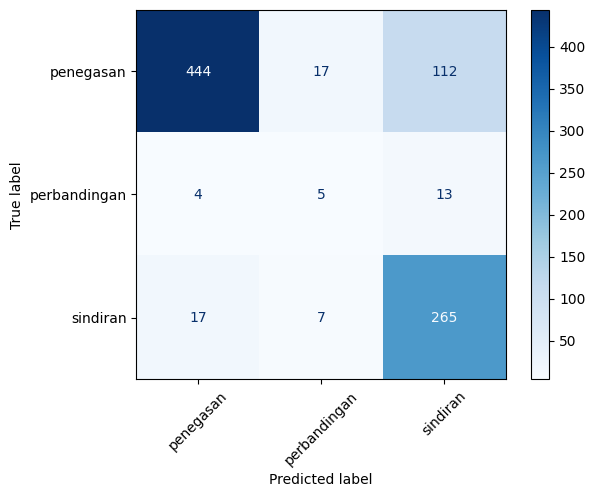

In [20]:
predictors = {
    'Majority': majority.predict,
    'NB': nb_search.best_estimator_.predict,
    'SVM': svm_search.best_estimator_.predict,
    'SVM+char': svmc_search.best_estimator_.predict,
    'IndoBERT': lambda t: bert_predict(t)[0],       # ensembel seed
}

val_preds = {name: np.asarray(predict(X_val)) for name, predict in predictors.items()}
val_scores = {name: f1_score(y_val, p, average='macro') for name, p in val_preds.items()}
print(pd.Series(val_scores).round(3).sort_values(ascending=False))
print('catatan: skor val IndoBERT sedikit optimis (val dipakai untuk early stopping dan temperature)')

best_name = max(val_scores, key=val_scores.get)   # dipilih di VALIDATION
y_pred_test = predictors[best_name](X_test)       # test dipakai sekali

print(best_name)
print(classification_report(y_test, y_pred_test, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, xticks_rotation=45, cmap='Blues')
plt.show()

In [21]:
res = bootstrap(
    (np.array(y_test), np.array(y_pred_test)),
    lambda t, p: f1_score(t, p, average='macro'),
    paired=True,          # keep true label and prediction together
    vectorized=False,
    n_resamples=1000,
    method='percentile',  # simple and always defined
    random_state=42,
)
test_f1 = f1_score(y_test, y_pred_test, average='macro')
ci = res.confidence_interval
print(f'test macro F1 = {test_f1:.3f}, 95% CI {ci.low:.3f}-{ci.high:.3f}')

test macro F1 = 0.611, 95% CI 0.561-0.662


In [22]:
def per_class_f1(y_true, y_pred):
    _, _, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    return pd.Series(f, index=LABELS)

f1_table = pd.DataFrame({n: per_class_f1(y_val, p) for n, p in val_preds.items()}).round(3)
f1_table.loc['macro'] = f1_table.mean().round(3)
print(f1_table)     # jika model A menang di kelas X dan B di kelas Y: pertimbangkan ensembel / routing

err = val_df.assign(pred=val_preds[best_name])
err = err[err['label'] != err['pred']]
for (true, pred), grp in err.groupby(['label', 'pred']):
    print(f'\n== benar={true} | prediksi={pred} | n={len(grp)}')
    for t in grp['Mentions'].head(5):
        print('  -', str(t)[:200].replace('\n', ' '))

              Majority     NB    SVM  SVM+char  IndoBERT
penegasan        0.837  0.777  0.880     0.883     0.883
perbandingan     0.000  0.100  0.000     0.000     0.273
sindiran         0.000  0.587  0.713     0.732     0.752
macro            0.279  0.488  0.531     0.538     0.636

== benar=penegasan | prediksi=perbandingan | n=20
  - Nilai tukar rupiah terhadap dolar AS kembali tertekan pada perdagangan awal pekan, Senin (13/7), dengan melemah dan menyentuh level Rp18.140 per dolar AS. Posisi ini berbalik arah dari penutupan perda
  - Nilai tukar rupiah terhadap dolar hari ini menyentuh titik terlemah sepanjang sejarah.   Dolar menembus Rp 17.500, namun Presiden Prabowo menanggapinya dengan santai.  Kontras dengan sikap itu, B.J. H
  - 5 DAPUR TERBESAR proyek ini ternyata dikuasai oleh yayasan-yayasan raksasa:   Yayasan Kemala Bhayangkari (Milik Polri)  Perserikatan Muhammadiyah Yayasan Kartika Jaya (TNI Angkatan Darat) Yayasan Adi 
  - Bocoran masa depan :  Investor asing hilang ➜

In [23]:
labels_v, conf_v = bert_predict(X_val)
for tau in [0.4, 0.5, 0.6, 0.7, 0.8]:
    keep = conf_v >= tau
    if keep.sum():
        print(f'tau={tau}: cakupan={keep.mean():.2f}, macro F1 yang dipertahankan='
              f'{f1_score(np.asarray(y_val)[keep], labels_v[keep], average="macro"):.3f}')
TAU = 0.6   # pilih dari tabel

tau=0.4: cakupan=0.99, macro F1 yang dipertahankan=0.646
tau=0.5: cakupan=0.95, macro F1 yang dipertahankan=0.666
tau=0.6: cakupan=0.89, macro F1 yang dipertahankan=0.672
tau=0.7: cakupan=0.77, macro F1 yang dipertahankan=0.694
tau=0.8: cakupan=0.22, macro F1 yang dipertahankan=0.436


# Predict Data

In [24]:
try:
    validate_export(predict_df)       # peringatan saja, tidak menghentikan notebook
except ValueError as e:
    print('peringatan skema:', e)

output_df = prepare_time(
    predict_df[['Date', 'Media', 'Type', 'Mentions', 'Sentiment', 'Author']])
start_date = output_df['Date'].min().strftime('%d %b %Y')
end_date = output_df['Date'].max().strftime('%d %b %Y')

output_df['text_clean'] = output_df['Mentions'].fillna('').apply(clean)
output_df['text_model'] = build_input(output_df)
mask = output_df['text_clean'].ne('')   # skip empty texts
print(f'predicting {mask.sum()} rows, skipping {(~mask).sum()} empty')

texts = output_df.loc[mask, 'text_model']
if best_name == 'IndoBERT':
    output_df.loc[mask, 'predicted_majas'], output_df.loc[mask, 'confidence'] = bert_predict(texts)
    output_df['majas_final'] = np.where(output_df['confidence'] >= TAU, output_df['predicted_majas'], 'tidak_yakin')
else:
    output_df.loc[mask, 'predicted_majas'] = predictors[best_name](texts)
output_df.head(20)

predicting 6188 rows, skipping 21 empty


,Date,Media,Type,Mentions,Sentiment,Author,text_clean,text_model,predicted_majas,confidence,majas_final
6208,2026-10-16 00:00:00,Twitter,rt,"RT Pelantikan 2 Pejabat TNI, Prabowo Tunjuk Maruli Simanjuntak Jadi Wakil Panglima dan Tandyo Budi Revita sebagai KSAD #TNI #Prabowo #MaruliSimanjuntak #TandyoBudi #KSAD #Kabarterdepan https://t.co/kAIJbNasF1 https://t.co/7EL5sO67mu",Negative,@kabarterdepanmr,"pelantikan 2 pejabat tni, tokoh tunjuk maruli simanjuntak jadi wakil panglima dan tandyo budi revita sebagai ksad tni tokoh marulisimanjuntak tandyobudi ksad kabarterdepan","sentimen_negative media_twitter . pelantikan 2 pejabat tni, tokoh tunjuk maruli simanjuntak jadi wakil panglima dan tandyo budi revita sebagai ksad tni tokoh marulisimanjuntak tandyobudi ksad kabarterdepan",sindiran,0.458024,tidak_yakin
6207,2026-10-16 00:00:03,Youtube,mention,???? INDONESIA MAJU #prabowo #viralvideo #youtubeshorts #viral #video #fyp #viralshorts #shorts,Positive,calonpemimpin,???? indonesia maju tokoh viralvideo youtubeshorts viral video fyp viralshorts shorts,sentimen_positive media_youtube . ???? indonesia maju tokoh viralvideo youtubeshorts viral video fyp viralshorts shorts,penegasan,0.734965,penegasan
6206,2026-10-16 00:00:06,Youtube,mention,"&quot;KALAU PAK PRABOWO SAMPAI AKHIR 2026 TIDAK MELAKUKAN APA-APA ATAS KELUARGA SOLO, BELIAU KALAH&quot;. For Partnership, Please Contact:\nbisnis@forumkeadilan.com\nhttps://wa.me/628119899090\n\nDapatkan informasi terkini isu-isu hukum dan politik di Indonesia dengan Forum Keadilan. Download aplikasinya sekarang!\nPlaystore https://tinyurl.com/forumkeadilanplaystore\nAppStore https://tinyurl.com/forumkeadilanapps\nPortal https://forumkeadilan.com/\n\nApakah Anda peduli dengan isu-isu keadilan sosial dan ingin berkontribusi dalam menciptakan perubahan positif? Forum Keadilan adalah tempat yang tepat untuk Anda! Ikuti kami sekarang di:\nYouTube https://www.youtube.com/@forumkeadilanTV\nInstagram https://www.instagram.com/forumkeadilantv\nFB https://www.facebook.com/forumkeadilandotcom\nTiktok https://www.tiktok.com/@forumkeadilantv\n\n#menukwulandari #prabowosubianto #gibranrakabumingraka #jokowi #irianajokowi #keluargasolo #kertenegara #aliansirakyatmenggugat #arm #wakilpresiden #pencalonanwapres #politikindonesia #politiknasional #madilog #podcastmadilog #margisyarif #presidensial #pemerintahanprabowo #beritanasional #forumkeadilan",Positive,Forum Keadilan TV,"""kalau bapak tokoh sampai akhir 2026 tidak melakukan apa-apa atas keluarga solo, beliau kalah"". for partnership, please contact: bisnis .com dapatkan informasi terkini isu-isu hukum dan politik di indonesia dengan forum keadilan. download aplikasinya sekarang! playstore appstore portal apakah anda peduli dengan isu-isu keadilan sosial dan ingin berkontribusi dalam menciptakan perubahan positif? forum keadilan adalah tempat yang tepat untuk anda! ikuti kami sekarang di: youtube instagram fb tiktok menukwulandari tokoh tokoh tokoh rakabumingraka tokoh iriana tokoh keluargasolo kertenegara aliansirakyatmenggugat arm wakilpresiden pencalonanwapres politikindonesia politiknasional madilog podcastmadilog margisyarif presidensial pemerintahan tokoh beritanasional forumkeadilan","sentimen_positive media_youtube . ""kalau bapak tokoh sampai akhir 2026 tidak melakukan apa-apa atas keluarga solo, beliau kalah"". for partnership, please contact: bisnis .com dapatkan informasi terkini isu-isu hukum dan politik di indonesia dengan forum keadilan. download aplikasinya sekarang! playstore appstore portal apakah anda peduli dengan isu-isu keadilan sosial dan ingin berkontribusi dalam menciptakan perubahan positif? forum keadilan adalah tempat yang tepat untuk anda! ikuti kami sekarang di: youtube instagram fb tiktok menukwulandari tokoh tokoh tokoh rakabumingraka tokoh iriana tokoh keluargasolo kertenegara aliansirakyatmenggugat arm wakilpresiden pencalonanwapres politikindonesia politiknasional madilog podcastmadilog margisyarif presidensial pemerintahan tok

In [25]:
print(output_df['predicted_majas'].value_counts(dropna=False, normalize=True))

if 'confidence' in output_df:
    # read the 10 least-confident predictions yourself: the fastest way
    # to catch a preprocessing mismatch between train and predict
    print(output_df['confidence'].describe())
    display(output_df.nsmallest(10, 'confidence')[['Mentions', 'predicted_majas', 'confidence']])

output_df.to_csv('predicted_results.csv', index=False, encoding='utf-8-sig')
files.download('predicted_results.csv')

predicted_majas
penegasan       0.626832
sindiran        0.278306
perbandingan    0.091480
NaN             0.003382
Name: proportion, dtype: float64
count    6188.000000
mean        0.733712
std         0.107200
min         0.353508
25%         0.699053
50%         0.738570
75%         0.764912
max         0.987538
Name: confidence, dtype: float64


,Mentions,predicted_majas,confidence
2882,HANCUR NEGARA INI DI REZIM.JOKOWI.DI.LANJUTKAN WOWO,perbandingan,0.353508
2554,"Kemaren kospi korea -10% Presidennya respon peduli sama kekhawatiran rakyatnya yang trading, jangan pada logout dari dunia. Ini IHSG langsung -8% bakal salahin antek apa lagi presiden Indonesia. Atau bahkan gak tau kondisi IHSG dari entah kapan",sindiran,0.374856
4897,"TANGISAN DI BALIK KORUPSI BNPB &amp; PERINGATAN KERAS PRABOWO. Waktu yang akhirnya menjawab kenapa Prabowo selalu keras soal kebocoran anggaran, apalagi urusan bencana. Bukan sekadar angka, ini soal nyawa. ?? #KorupsiBNPB #PrabowoSubianto #DanaBencana #TimeTellsTheTruth #KPK",sindiran,0.382936
5518,"Ini kalo di terusin video bisa buat emosi dengar pernyataan si wowo sumpah ga guna banget dia jadi presiden, lu jadi presiden di minta tanggung jawab B4n954t, pajak negara lu pake buat korupsi demi lahan sawit Bajingan emang punya presiden. [RE FaiNomady]",sindiran,0.385281
4982,WAKTU YANG MENJAWAB: ALASAN PRABOWO KERAS SOAL DANA BENCANA. BNPB kena OTT KPK soal Dana Siap Pakai (DSP) bencana. Sekarang publik baru sadar kenapa Prabowo selama ini selalu ngegas soal kebocoran anggaran dan ngancam keras koruptor dana bencana. Waktu yang membuktikan. ?? #Prabowo #KorupsiBNPB #KPK #KorupsiBencana #TimeTellsTheTruth,perbandingan,0.385296
3922,Pecah Kongsi Wiwi Vs Wowo #prabowo #jokowi #shorts,sindiran,0.387814
4482,Kapolri Baru Akan Kuak Kasvs Di Era Lama #prabowo #kapolri #shorts,perbandingan,0.387994
2928,Prabowo gebrak gebrak ndak jelas,sindiran,0.393360
5822,"RT alasan partai-partai belum kompak memakzulkan gibran menurut bocor alus partai-partai belum kompak karena saling menunggu, tidak ada yang mau maju duluan gerindra memilih diam, tidak membesarkan dan tidak mengecilkan putusan mk dpr sedang reses, jadi banyak yang mau lihat dulu setelah reses beberapa partai disebut ingin hak angket tapi menunggu pdip maju duluan pdip tidak mau maju sendirian karena suaranya sedikit dan takut terlihat melawan jokowi nasdem sempat bikin draf surat pemakzulan lalu dicabut setelah ramai istana bilang putusan mk tidak mengenai prabowo karena ini sengketa sebelum pelantikan putusan mk sendiri lunak, memakai kata “tidak menemukan” ijazah, bukan “tidak memiliki” mk bilang penilaian pencalonan bisa dibawa ke lembaga lain, tanpa perintah jelas ke dpr jokowi disebut khawatir kasus dibawa ke ptun dan ma",penegasan,0.394563
5421,"RT alasan partai-partai belum kompak memakzulkan gibran menurut bocor alus partai-partai belum kompak karena saling menunggu, tidak ada yang mau maju duluan gerindra memilih diam, tidak membesarkan dan tidak mengecilkan putusan mk dpr sedang reses, jadi banyak yang mau lihat dulu setelah reses beberapa partai disebut ingin hak angket tapi menunggu pdip maju duluan pdip tidak mau maju sendirian karena suaranya sedikit dan takut terlihat melawan jokowi nasdem sempat bikin draf surat pemakzulan lalu dicabut setelah ramai istana bilang putusan mk tidak mengenai prabowo karena ini sengketa sebelum pelantikan putusan mk sendiri lunak, memakai kata “tidak menemukan” ijazah, bukan “tidak memiliki” mk bilang penilaian pencalonan bisa dibawa ke lembaga lain, tanpa perintah jelas ke dpr jokowi disebut khawatir kasus dibawa ke ptun dan ma",penegasan,0.394563


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
pool = output_df[mask].drop_duplicates(subset='text_clean')
# sampel berstrata: sampai 50 per kelas prediksi (sampel acak 200 hampir tak memuat kelas 3%)
sample = pd.concat([grp.sample(min(len(grp), 50), random_state=42)
                    for _, grp in pool.groupby('predicted_majas')])
sample[['Mentions', 'text_clean', 'predicted_majas']].assign(label_manual='').to_excel(
    'to_label_manually.xlsx', index=False)
files.download('to_label_manually.xlsx')
# catatan: ini memberi PRECISION per kelas yang adil, bukan recall. Untuk recall, label juga sampel acak biasa.
# isi kolom label_manual lalu unggah file kembali ke Colab

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
checked = pd.read_excel('to_label_manually.xlsx').dropna(subset=['label_manual'])
if checked.empty:
    print('label_manual is still empty: fill it in first, then upload the file again')
else:
    print(classification_report(checked['label_manual'], checked['predicted_majas'], zero_division=0))

label_manual is still empty: fill it in first, then upload the file again


In [28]:
iaa = training_df2.sample(250, random_state=1)
iaa[['Mentions']].assign(label_2='').to_excel('iaa_to_label.xlsx', index_label='idx')
files.download('iaa_to_label.xlsx')
# isi kolom label_2 memakai nama label yang SAMA (sindiran/perbandingan/penegasan/pertentangan/netral)

# %% [26] Cohen's kappa, stage B: after the file is filled and uploaded as iaa_filled.xlsx
back = pd.read_excel('iaa_filled.xlsx', index_col='idx')
old = training_df2.loc[back.index, 'label']
new = back['label_2'].astype(str).str.strip().str.lower()
print("Cohen's kappa:", round(cohen_kappa_score(old, new), 3))
print(pd.crosstab(old, new))     # pasangan kelas mana yang paling seri

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FileNotFoundError: [Errno 2] No such file or directory: 'iaa_filled.xlsx'